# Delta Air Lines: Flight Delay Prediction

**Applied Machine Learning - Fall 2026**

**Business question:** How can Delta Air Lines use historical flight information to anticipate arrival delays and support proactive operational decision-making?

**Machine learning question:** Using only information available before scheduled departure, how accurately can we predict whether a Delta-operated flight will arrive at least 15 minutes late, and which pre-departure flight characteristics are most predictive of delay risk?

**Scope:** U.S. BTS Reporting Carrier On-Time Performance records for 2025. We predict `ARR_DEL15` for completed flights with observed arrival outcomes. Cancelled and diverted flights are excluded from this binary classification task.

**Prediction timing:** Before scheduled departure. Actual departure/arrival outcomes must never be predictors.

This notebook documents the data processing and modelling workflow. All findings should be based on the actual output generated below.

## 1. Import libraries and configure paths

Run Jupyter from the repository root, where `flight_delay_analysis.ipynb` and `data/` are next to each other.

In [1]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

DATA_DIR = Path("data")
MONTHLY_FILES = [DATA_DIR / f"{month:02d}-2025.csv" for month in range(1, 13)]

missing_files = [str(path) for path in MONTHLY_FILES if not path.is_file()]
if missing_files:
    raise FileNotFoundError(f"Missing BTS monthly file(s): {missing_files}")

print(f"Found all {len(MONTHLY_FILES)} monthly files.")

Matplotlib is building the font cache; this may take a moment.


Found all 12 monthly files.


## 2. Data collection and integration

We combine the 12 monthly BTS files by **row-wise concatenation**, not a database-style merge. We verify the expected columns and check that each file covers its intended month. To reduce memory usage, we retain only Delta-operated records (`DL`) while loading. The original month-level row counts are retained for documentation.

In [9]:
EXPECTED_COLUMNS = [
    "FL_DATE", "OP_UNIQUE_CARRIER", "ORIGIN", "DEST",
    "CRS_DEP_TIME", "CRS_ARR_TIME", "ARR_DEL15",
    "CANCELLED", "DIVERTED", "CRS_ELAPSED_TIME", "DISTANCE"
]

monthly_delta = []
load_log = []

for month, file_path in enumerate(MONTHLY_FILES, start=1):
    monthly = pd.read_csv(file_path, usecols=lambda col: col in EXPECTED_COLUMNS)
    missing_columns = sorted(set(EXPECTED_COLUMNS) - set(monthly.columns))
    if missing_columns:
        raise ValueError(f"{file_path.name} is missing columns: {missing_columns}")

    monthly["FL_DATE"] = pd.to_datetime(
    monthly["FL_DATE"],
    format="%m/%d/%Y %I:%M:%S %p",
    errors="raise"
)
    if monthly["FL_DATE"].isna().any():
        raise ValueError(f"Unparseable dates in {file_path.name}")
    if not ((monthly["FL_DATE"].dt.year == 2025) &
            (monthly["FL_DATE"].dt.month == month)).all():
        raise ValueError(f"Unexpected dates in {file_path.name}")

    delta_month = monthly.loc[
        monthly["OP_UNIQUE_CARRIER"] == "DL", EXPECTED_COLUMNS
    ].copy()

    load_log.append({
        "month": month,
        "all_reporting_carrier_rows": len(monthly),
        "delta_rows": len(delta_month)
    })
    monthly_delta.append(delta_month)
    print(f"{file_path.name}: {len(monthly):,} total, {len(delta_month):,} DL")
    del monthly

df = pd.concat(monthly_delta, ignore_index=True)
load_summary = pd.DataFrame(load_log)
print(f"\nTotal Delta rows in 2025: {len(df):,}")
display(load_summary)

01-2025.csv: 539,747 total, 76,306 DL
02-2025.csv: 504,884 total, 71,333 DL
03-2025.csv: 600,872 total, 84,487 DL
04-2025.csv: 583,950 total, 84,188 DL
05-2025.csv: 605,648 total, 89,931 DL
06-2025.csv: 611,575 total, 91,122 DL
07-2025.csv: 631,428 total, 94,066 DL
08-2025.csv: 602,378 total, 90,313 DL
09-2025.csv: 562,439 total, 84,875 DL
10-2025.csv: 605,844 total, 90,097 DL
11-2025.csv: 570,550 total, 84,475 DL
12-2025.csv: 582,304 total, 85,139 DL

Total Delta rows in 2025: 1,026,332


,month,all_reporting_carrier_rows,delta_rows
0,1,539747,76306
1,2,504884,71333
2,3,600872,84487
3,4,583950,84188
4,5,605648,89931
5,6,611575,91122
6,7,631428,94066
7,8,602378,90313
8,9,562439,84875
9,10,605844,90097


## 3. Data understanding and quality checks

Inspect the dataset structure and missing values **before** deciding how to handle them. Distinguish cancellations, diversions, and missing observed arrival outcomes. Report the number of observations removed and why.

In [3]:
display(df.head())
print("Shape:", df.shape)
print("Date range:", df["FL_DATE"].min(), "to", df["FL_DATE"].max())
print("Unique dates:", df["FL_DATE"].nunique())
print("Unique origin airports:", df["ORIGIN"].nunique())
print("Unique destination airports:", df["DEST"].nunique())

missingness = (
    df.isna().sum().rename("missing_count").to_frame()
    .assign(missing_pct=lambda x: 100 * x["missing_count"] / len(df))
    .sort_values("missing_count", ascending=False)
)
display(missingness)

print("Cancelled:", int((df["CANCELLED"] == 1).sum()))
print("Diverted:", int((df["DIVERTED"] == 1).sum()))
print("Missing arrival target:", int(df["ARR_DEL15"].isna().sum()))
print("Exact duplicate rows (review before removing):", int(df.duplicated().sum()))

,FL_DATE,OP_UNIQUE_CARRIER,ORIGIN,DEST,CRS_DEP_TIME,CRS_ARR_TIME,ARR_DEL15,CANCELLED,DIVERTED,CRS_ELAPSED_TIME,DISTANCE
0,2025-01-01,DL,ABQ,ATL,635,1132,0.0,0.0,0.0,177.0,1269.0
1,2025-01-01,DL,ABQ,ATL,1135,1633,0.0,0.0,0.0,178.0,1269.0
2,2025-01-01,DL,ABQ,MSP,800,1139,0.0,0.0,0.0,159.0,981.0
3,2025-01-01,DL,ALB,ATL,605,859,0.0,0.0,0.0,174.0,853.0
4,2025-01-01,DL,ALB,ATL,1413,1705,0.0,0.0,0.0,172.0,853.0


Shape: (1026332, 11)
Date range: 2025-01-01 00:00:00 to 2025-12-31 00:00:00
Unique dates: 365
Unique origin airports: 153
Unique destination airports: 153


,missing_count,missing_pct
ARR_DEL15,13905,1.354825
FL_DATE,0,0.000000
OP_UNIQUE_CARRIER,0,0.000000
ORIGIN,0,0.000000
DEST,0,0.000000
CRS_DEP_TIME,0,0.000000
CRS_ARR_TIME,0,0.000000
CANCELLED,0,0.000000
DIVERTED,0,0.000000
CRS_ELAPSED_TIME,0,0.000000


Cancelled: 11114
Diverted: 2791
Missing arrival target: 13905
Exact duplicate rows (review before removing): 0


## 4. Define the modelling population

The target is defined only for completed flights with a known outcome. We exclude cancelled or diverted flights and observations with missing `ARR_DEL15`. We do **not** replace missing target values with 0. Note that this limits the scope: the model does not predict cancellations or diversions.

In [4]:
valid_status = (df["CANCELLED"] == 0) & (df["DIVERTED"] == 0)
valid_target = df["ARR_DEL15"].isin([0, 1])
clean = df.loc[valid_status & valid_target].copy()
clean["ARR_DEL15"] = clean["ARR_DEL15"].astype(int)

print(f"Before cleaning: {len(df):,} Delta flights")
print(f"After cleaning:  {len(clean):,} completed flights with known target")
print(f"Excluded:        {len(df) - len(clean):,} rows")
print(f"Arrival delay rate: {clean['ARR_DEL15'].mean():.2%}")
display(clean["ARR_DEL15"].value_counts().rename(index={0: "On time (<15 min late)", 1: "Delayed (>=15 min late)"}).to_frame("flights"))

Before cleaning: 1,026,332 Delta flights
After cleaning:  1,012,427 completed flights with known target
Excluded:        13,905 rows
Arrival delay rate: 19.79%


,flights
ARR_DEL15,
On time (<15 min late),812025
Delayed (>=15 min late),200402


## 5. Exploratory data analysis (EDA)

**Descriptive questions:** What fraction of flights arrived 15+ minutes late? Does delay incidence differ by month, weekday, scheduled departure hour, or origin airport? These are descriptive associations, not causal effects. Seasonal results will inform the discussion of 2025 representativeness and evaluation design.

,flights,delay_rate,delay_rate_pct
MONTH,,,
1,74025,0.193205,19.320500
2,71061,0.199702,19.970166
3,83857,0.184206,18.420645
4,83560,0.177705,17.770464
5,89472,0.220114,22.011356
6,89155,0.261702,26.170153
7,92245,0.248447,24.844707
8,89322,0.170260,17.026041
9,84630,0.123845,12.384497


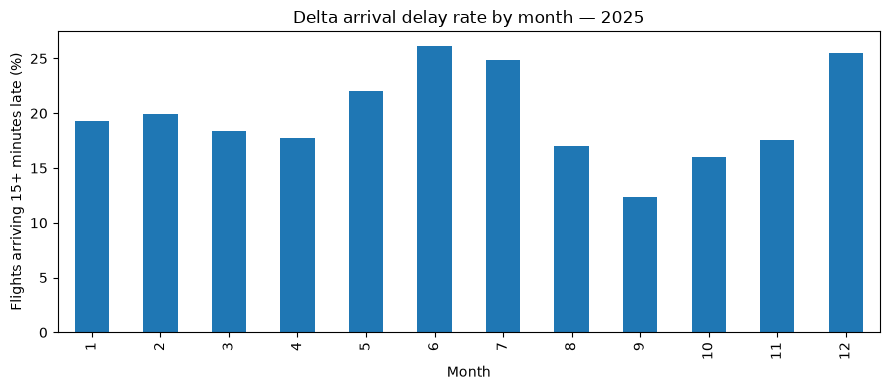

In [5]:
clean["MONTH"] = clean["FL_DATE"].dt.month
clean["DAY_OF_WEEK"] = clean["FL_DATE"].dt.dayofweek + 1  # Monday=1, Sunday=7

# CRS_DEP_TIME is stored as a four-digit local HHMM scheduled clock time.
clean["DEP_HOUR"] = pd.to_numeric(clean["CRS_DEP_TIME"], errors="coerce") // 100
clean.loc[~clean["DEP_HOUR"].between(0, 23), "DEP_HOUR"] = np.nan

monthly = (clean.groupby("MONTH")["ARR_DEL15"]
           .agg(flights="size", delay_rate="mean")
           .reindex(range(1, 13)))
monthly["delay_rate_pct"] = 100 * monthly["delay_rate"]
display(monthly)

fig, ax = plt.subplots(figsize=(9, 4))
monthly["delay_rate_pct"].plot(kind="bar", ax=ax)
ax.set(title="Delta arrival delay rate by month — 2025",
       xlabel="Month", ylabel="Flights arriving 15+ minutes late (%)")
plt.tight_layout()
plt.show()

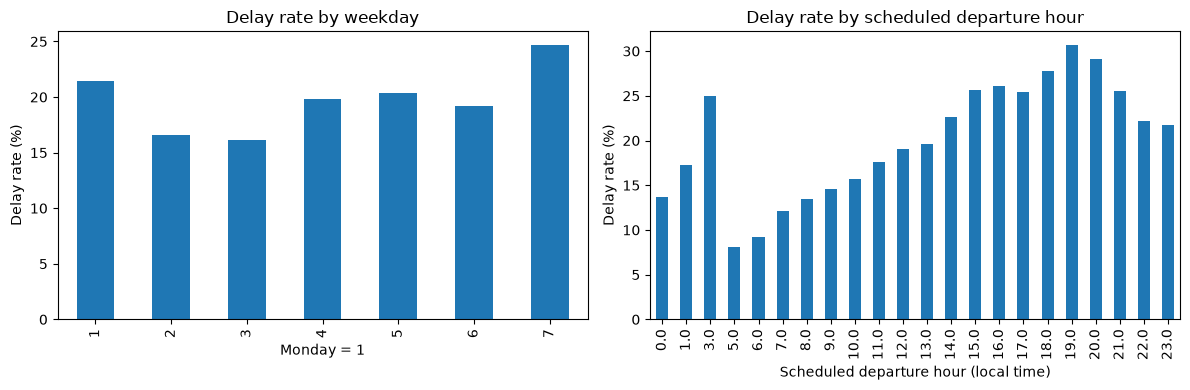

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

weekday = clean.groupby("DAY_OF_WEEK")["ARR_DEL15"].mean().mul(100)
weekday.plot(kind="bar", ax=axes[0])
axes[0].set(title="Delay rate by weekday", xlabel="Monday = 1", ylabel="Delay rate (%)")

hourly = clean.groupby("DEP_HOUR")["ARR_DEL15"].mean().mul(100)
hourly.plot(kind="bar", ax=axes[1])
axes[1].set(title="Delay rate by scheduled departure hour",
            xlabel="Scheduled departure hour (local time)", ylabel="Delay rate (%)")

plt.tight_layout()
plt.show()

In [7]:
origin_summary = (clean.groupby("ORIGIN")["ARR_DEL15"]
                  .agg(flights="size", delay_rate="mean"))
origin_summary = origin_summary.loc[origin_summary["flights"] >= 1000]
origin_summary = origin_summary.sort_values("delay_rate", ascending=False)
origin_summary["delay_rate_pct"] = 100 * origin_summary["delay_rate"]
print("Origin airports with >=1,000 completed Delta flights in 2025")
display(origin_summary.head(10))

Origin airports with >=1,000 completed Delta flights in 2025


,flights,delay_rate,delay_rate_pct
ORIGIN,,,
EWR,6414,0.291082,29.108201
MIA,11017,0.272942,27.294182
LGA,28462,0.270993,27.099290
ORD,10875,0.260966,26.096552
BOS,25511,0.241504,24.150367
MCO,20548,0.238807,23.880670
FLL,12360,0.237540,23.754045
PBI,7061,0.234669,23.466931
ROC,1022,0.232877,23.287671


### EDA findings — complete after running the code

Document only what the actual results show:

- **Sample size:** [insert number of completed Delta flights]
- **Overall delay rate:** [insert %]
- **Seasonality:** [describe high/low months and whether the differences are substantial]
- **Scheduled departure hour / airports:** [describe relevant patterns]
- **Important caveat:** One calendar year may reflect unusual year-specific conditions; monthly variation does not by itself prove the patterns recur in future years.

Do not assume summer or December has the highest delay rate before examining the data.

## 6. Feature selection and leakage audit

Predictors must be available **before scheduled departure**.

| Role | Variables | Notes |
| --- | --- | --- |
| Target | `ARR_DEL15` | Binary observed arrival outcome |
| Candidate predictors | `ORIGIN`, `DEST`, `CRS_DEP_TIME`, `CRS_ARR_TIME`, `CRS_ELAPSED_TIME`, `DISTANCE`, `MONTH`, `DAY_OF_WEEK` | Derived calendar features are based on `FL_DATE` |
| Filtering only | `OP_UNIQUE_CARRIER`, `CANCELLED`, `DIVERTED` | Not predictors in the first modelling setup |
| Date for splitting | `FL_DATE` | Preserve date for possible temporal evaluation |

**Important:** Actual arrival/departure times, actual delays, and post-departure causes are excluded. `CRS_DEP_TIME` and `CRS_ARR_TIME` are local clock times; do not subtract them to estimate duration across time zones. Use `CRS_ELAPSED_TIME` instead.

**Target population caveat:** At deployment time, whether a flight will ultimately be cancelled or diverted is unknown. This model estimates delay risk conditional on the completed-flight population used for training; discuss this scope limitation in the report.

In [8]:
FEATURES = [
    "ORIGIN", "DEST", "CRS_DEP_TIME", "CRS_ARR_TIME",
    "CRS_ELAPSED_TIME", "DISTANCE", "MONTH", "DAY_OF_WEEK"
]
TARGET = "ARR_DEL15"

print("Candidate features:", FEATURES)
print("Any missing feature values?")
display(clean[FEATURES].isna().sum().to_frame("missing_count"))

Candidate features: ['ORIGIN', 'DEST', 'CRS_DEP_TIME', 'CRS_ARR_TIME', 'CRS_ELAPSED_TIME', 'DISTANCE', 'MONTH', 'DAY_OF_WEEK']
Any missing feature values?


,missing_count
ORIGIN,0
DEST,0
CRS_DEP_TIME,0
CRS_ARR_TIME,0
CRS_ELAPSED_TIME,0
DISTANCE,0
MONTH,0
DAY_OF_WEEK,0


## 7. Next steps: split, preprocessing, modelling and evaluation

**Do not train models on the full dataset yet.** First agree on the evaluation target:

1. A random stratified split estimates performance on similar within-2025 observations but can be optimistic when nearby flights share unobserved disruptions.
2. A chronological split better resembles prediction on later periods, but one year's earlier months do not include a complete seasonal cycle.
3. Decide on a primary evaluation and, if feasible, a separate temporal robustness check. Keep final test data untouched while tuning.
4. Fit imputers, encoders and scalers **only on the training portion**, preferably using scikit-learn `Pipeline`/`ColumnTransformer`.
5. Start with a `DummyClassifier` and Logistic Regression. Add Decision Tree and/or Random Forest if useful.
6. Evaluate precision, recall, F1, ROC-AUC, confusion matrix, errors by subgroup and practical business implications.

**Write-up:** The notebook shows all code, checks, results and brief interpretation; the report focuses on the key design decisions, outcomes and limitations.